# 2D Flight Trajectory Simulator: Numerical Integration of ODEs

This notebook simulates the 2D launch trajectory of a rocket operating under atmospheric drag and wind vectors. The core of the program is a custom numerical integrator utilizing Heun's Method (a 2nd-order Runge-Kutta algorithm) to solve the non-linear equations of motion.

## Equations of Motion
The state of the vehicle is defined by the vector $[x, y, v_x, v_y]$. The program integrates the following system of first-order Ordinary Differential Equations (ODEs):

$$ \frac{dx}{dt} = v_x $$
$$ \frac{dy}{dt} = v_y $$
$$ \frac{dv_x}{dt} = \frac{F_x(t) + D_x}{m(t)} $$
$$ \frac{dv_y}{dt} = \frac{F_y(t) + D_y}{m(t)} - g $$

Thrust is dynamically aligned with the velocity vector, while aerodynamic drag strictly opposes the air-relative velocity vector (accounting for ambient wind).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
G = 32.174  # ft/s^2
M0 = 1.1 / G  # Initial mass in slugs
ISP = 165.0
D_REF = 3.1 / 12.0  # ft
A_REF = np.pi * (D_REF / 2.0)**2
RHO = 0.00237  # Air density, slugs/ft^3
T_BURN = 2.0  # s
MF = 0.0308  # Final mass in slugs
DT = 0.01  # Time step, s

launch_angle_g = 0

def get_thrust(t, F_const=None):
    if F_const is not None:
        return F_const if t <= T_BURN else 0.0
    if t <= T_BURN:
        return 18.0 - 9.0 * t
    else:
        return 0.0

def get_mass(t):
    if t <= T_BURN:
        propellant_mass_used = (18.0*t - 4.5*t**2) / (G*ISP)
        return M0 - propellant_mass_used
    else:
        return MF

def derivatives(t, state, wind_v, sim_params):
    x, y, vx, vy = state
    mass = get_mass(t)
    thrust = get_thrust(t, sim_params.get('F_const'))
    current_cd = sim_params.get('CD', 0.3)

    v_mag = np.sqrt(vx**2 + vy**2)

    # Thrust components
    if v_mag > 1e-6:
        fx = thrust * vx / v_mag
        fy = thrust * vy / v_mag
    else:
        fx = thrust * np.cos(np.deg2rad(launch_angle_g))
        fy = thrust * np.sin(np.deg2rad(launch_angle_g))

    # Drag components (Air-relative velocity)
    v_air_x = vx - wind_v[0]
    v_air_y = vy - wind_v[1]
    v_air_mag = np.sqrt(v_air_x**2 + v_air_y**2)

    if v_air_mag > 1e-6:
        drag_force = 0.5 * RHO * v_air_mag**2 * current_cd * A_REF
        dx = -drag_force * v_air_x / v_air_mag
        dy = -drag_force * v_air_y / v_air_mag
    else:
        dx, dy = 0, 0

    ax = (fx + dx) / mass
    ay = (fy + dy) / mass - G

    return np.array([vx, vy, ax, ay])

## Numerical Integrator: Heun's Method
To step the simulation forward in time, the system state is updated using a 2nd-order Runge-Kutta predictor-corrector method:

$$ \tilde{y}_{i+1} = y_i + \Delta t \cdot f(t_i, y_i) $$
$$ y_{i+1} = y_i + \frac{\Delta t}{2} \left[ f(t_i, y_i) + f(t_{i+1}, \tilde{y}_{i+1}) \right] $$

In [2]:
def run_simulation(launch_angle, wind_mph, sim_params={}):
    global launch_angle_g
    launch_angle_g = launch_angle

    state = np.array([0.0, 0.0, 0.0, 0.0]) # x, y, vx, vy
    t = 0.0
    wind_fps = wind_mph * 5280.0 / 3600.0
    wind_v = np.array([wind_fps, 0.0])

    history = {'t': [], 'x': [], 'y': [], 'v': [], 'a': []}

    while True:
        v_mag = np.sqrt(state[2]**2 + state[3]**2)
        k1_for_hist = derivatives(t, state, wind_v, sim_params)
        a_mag = np.sqrt(k1_for_hist[2]**2 + k1_for_hist[3]**2)

        history['t'].append(t)
        history['x'].append(state[0])
        history['y'].append(state[1])
        history['v'].append(v_mag)
        history['a'].append(a_mag)

        # Heun's Method Integration
        k1 = derivatives(t, state, wind_v, sim_params)
        state_p = state + DT * k1
        k2 = derivatives(t + DT, state_p, wind_v, sim_params)
        state = state + (DT / 2.0) * (k1 + k2)

        t += DT
        if state[1] < 0 and t > 1: # Ground impact
            break

    return history

## Algorithm Verification
Before simulating complex flight regimes, the numerical solver is validated against an exact analytical solution for a simplified 1D vertical launch (Zero Drag, Constant Thrust).


--- Algorithm Verification ---
Parameter                 | Analytical (ft) | Numerical (ft) 
------------------------------------------------------------
Burnout Height            | 486.7           | 490.11         
Total Height (Apogee)     | 4212.7          | 4351.99        
------------------------------------------------------------


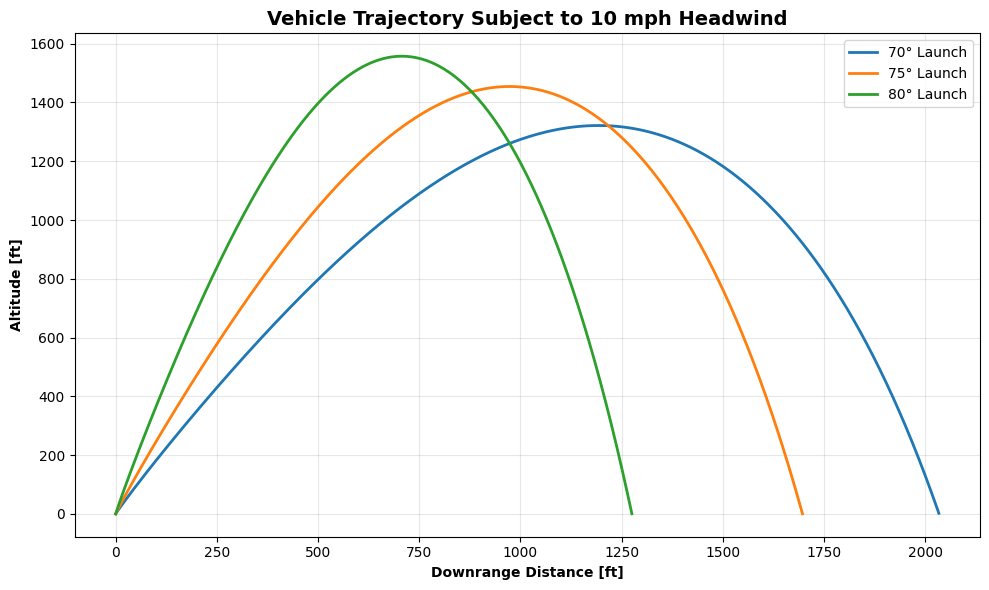

In [3]:
# 1. Verification Test
verification_params = {'CD': 0.0, 'F_const': 9.0}
hist_verify = run_simulation(launch_angle=90, wind_mph=0, sim_params=verification_params)
num_burnout_h = hist_verify['y'][int(2.0/DT)]
num_total_h = max(hist_verify['y'])

print("\n--- Algorithm Verification ---")
print(f"{'Parameter':<25} | {'Analytical (ft)':<15} | {'Numerical (ft)':<15}")
print("-" * 60)
print(f"{'Burnout Height':<25} | {'486.7':<15} | {num_burnout_h:<15.2f}")
print(f"{'Total Height (Apogee)':<25} | {'4212.7':<15} | {num_total_h:<15.2f}")
print("-" * 60)

# 2. Main Simulation & Plotting
plt.figure(figsize=(10, 6))
for angle in [70, 75, 80]:
    results = run_simulation(launch_angle=angle, wind_mph=10, sim_params={})
    plt.plot(results['x'], results['y'], label=f'{angle}° Launch', linewidth=2)

plt.title('Vehicle Trajectory Subject to 10 mph Headwind', fontweight='bold', fontsize=14)
plt.xlabel('Downrange Distance [ft]', fontweight='bold')
plt.ylabel('Altitude [ft]', fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()